<a href="https://colab.research.google.com/github/mayankbhambhu/Python-Application-Programming/blob/main/Pratical_10_Iris_Seaborn_Visualization_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis of the Iris Dataset Using Seaborn

**Objective:** Visualize morphological measurements across three *Iris* species (*Iris setosa*, *Iris versicolor*, and *Iris virginica*) using six core Seaborn chart types—**Scatter Plots**, **Density Plots**, **Violin Plots**, **Heatmaps**, **Joint Plots**, and **Pair Plots**—followed by a structured statistical and visual analysis after each visualization.

## 0. Environment Setup & Dataset Inspection
In this section, we import the required Python libraries (`seaborn`, `matplotlib.pyplot`, and `pandas`), configure a consistent visual style, and load the built-in **Iris** dataset.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set global Seaborn aesthetic theme
sns.set_theme(style="whitegrid", palette="Set2", context="notebook")

# Load the Iris dataset
iris = sns.load_dataset("iris")

# Inspect structure and summary statistics
print(f"Dataset Shape: {iris.shape[0]} rows, {iris.shape[1]} columns\n")
print("Class Distribution:\n", iris["species"].value_counts(), "\n")
display(iris.head())
display(iris.describe().round(2))

Dataset Shape: 150 rows, 5 columns

Class Distribution:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64 



,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


---
## 1. Scatter Plots
Scatter plots examine bivariate relationships between two continuous variables while encoding species identity via color (`hue`) and marker shape (`style`).

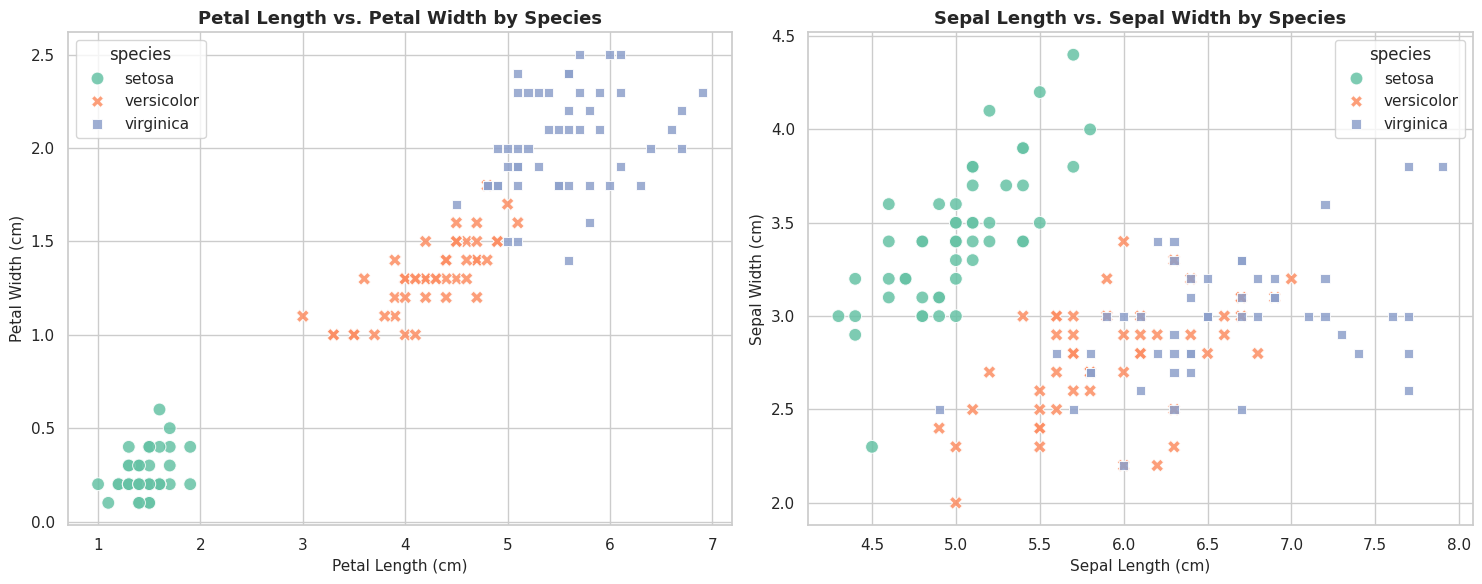

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Petal Length vs. Petal Width
sns.scatterplot(
    data=iris,
    x="petal_length",
    y="petal_width",
    hue="species",
    style="species",
    s=85,
    alpha=0.85,
    ax=axes[0]
)
axes[0].set_title("Petal Length vs. Petal Width by Species", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Petal Length (cm)", fontsize=11)
axes[0].set_ylabel("Petal Width (cm)", fontsize=11)

# Subplot 2: Sepal Length vs. Sepal Width
sns.scatterplot(
    data=iris,
    x="sepal_length",
    y="sepal_width",
    hue="species",
    style="species",
    s=85,
    alpha=0.85,
    ax=axes[1]
)
axes[1].set_title("Sepal Length vs. Sepal Width by Species", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Sepal Length (cm)", fontsize=11)
axes[1].set_ylabel("Sepal Width (cm)", fontsize=11)

plt.tight_layout()
plt.show()

### Analysis of Scatter Plots
1. **Petal Dimensions (`petal_length` vs. `petal_width`):**
   * **Strong Positive Linear Trend:** Across the dataset, petal width increases proportionally with petal length.
   * **Clear Species Clustering:** *Iris setosa* forms a tightly grouped, linearly separable cluster in the bottom-left region (`petal_length` $\approx 1.0 - 1.9\text{ cm}$, `petal_width` $\approx 0.1 - 0.6\text{ cm}$).
   * **Moderate Boundary Overlap:** *Iris versicolor* occupies the middle range (`petal_length` $\approx 3.0 - 5.1\text{ cm}$), while *Iris virginica* occupies the upper-right range (`petal_length` $\approx 4.5 - 6.9\text{ cm}$), with minor overlap near `petal_length` $\approx 4.5 - 5.1\text{ cm}$.
2. **Sepal Dimensions (`sepal_length` vs. `sepal_width`):**
   * **Distinct *Setosa* Profile:** *Setosa* stands apart with shorter sepals (`mean = 5.01 cm`) yet notably wider sepals (`mean = 3.43 cm`) than the other two species.
   * **Substantial Overlap Between *Versicolor* and *Virginica*:** Unlike petal measurements, sepal measurements exhibit heavy mixing between *versicolor* and *virginica*, indicating that sepal dimensions alone are much weaker predictors for distinguishing those two species.

---
## 2. Density Plots (Kernel Density Estimation)
Density plots estimate the continuous probability density function (PDF) of each feature, revealing distribution peaks (modes), spread, skewness, and inter-species overlap.

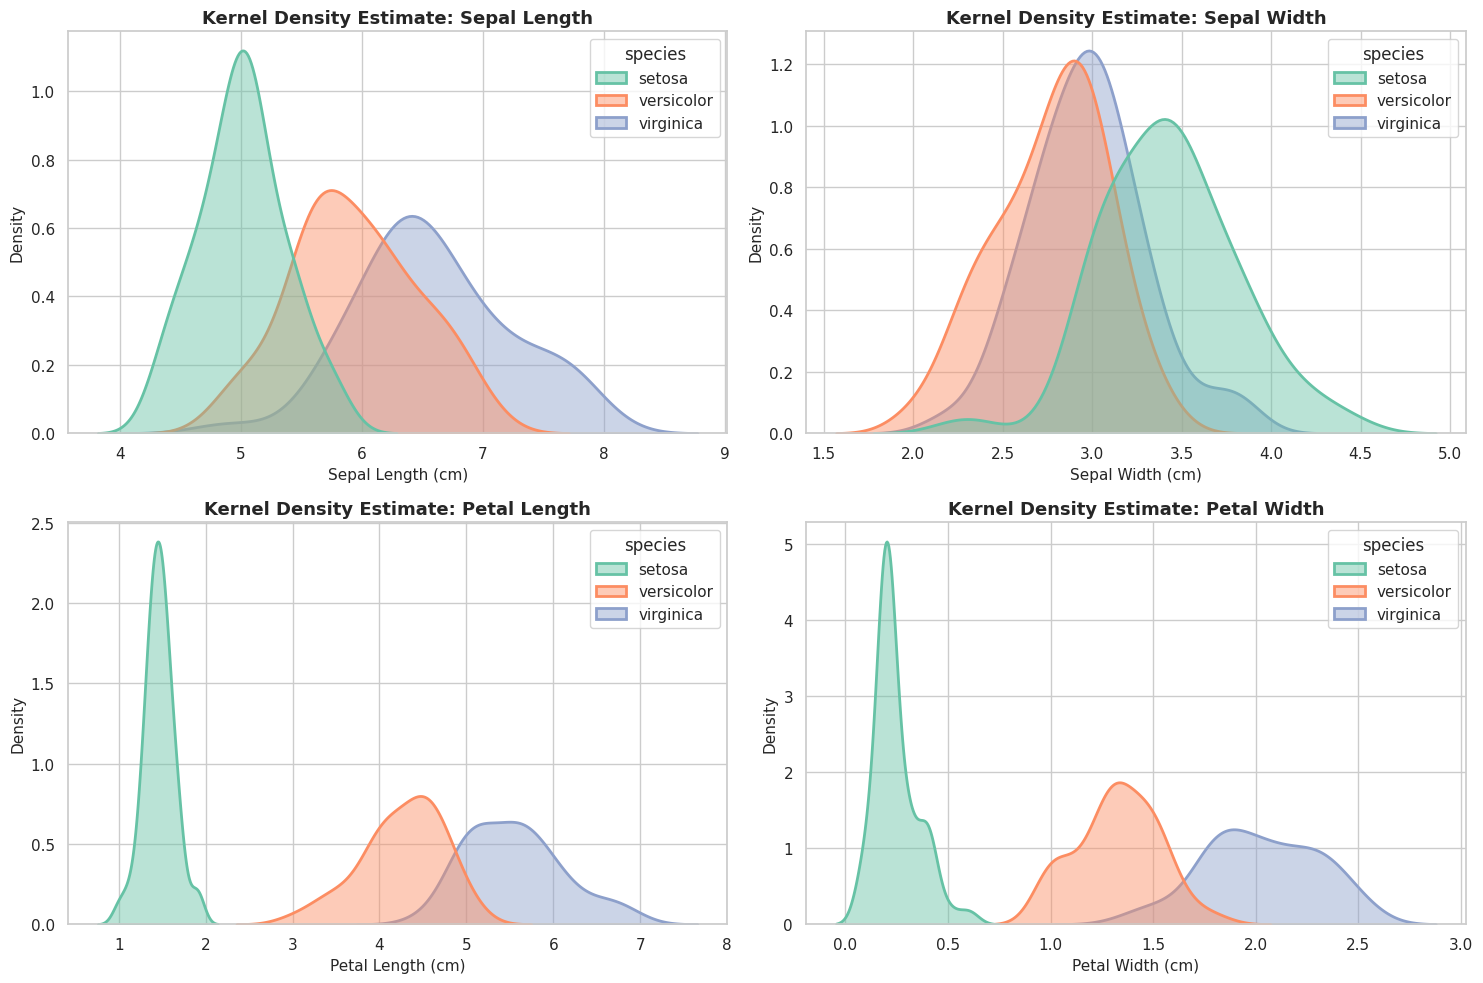

In [3]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, feature in zip(axes.flat, features):
    sns.kdeplot(
        data=iris,
        x=feature,
        hue="species",
        fill=True,
        common_norm=False,
        alpha=0.45,
        linewidth=2,
        ax=ax
    )
    ax.set_title(f"Kernel Density Estimate: {feature.replace('_', ' ').title()}", fontsize=13, fontweight="bold")
    ax.set_xlabel(f"{feature.replace('_', ' ').title()} (cm)", fontsize=11)
    ax.set_ylabel("Density", fontsize=11)

plt.tight_layout()
plt.show()

### Analysis of Density Plots
1. **Unimodal Class Distributions:** Every individual species exhibits a roughly bell-shaped (unimodal) distribution across all four measurements, indicating homogeneous within-species morphology.
2. **Sharpest Separation in Petal Features:**
   * In `petal_length` and `petal_width`, *setosa* displays a tall, narrow density curve (low standard deviation: $\text{SD} = 0.17\text{ cm}$ for length, $0.11\text{ cm}$ for width) completely isolated from *versicolor* and *virginica*.
   * *Versicolor* and *virginica* show distinct peaks (`petal_length` peaks near $4.35\text{ cm}$ vs. $5.55\text{ cm}$; `petal_width` peaks near $1.30\text{ cm}$ vs. $2.00\text{ cm}$) with only minor tail overlap.
3. **High Overlap in Sepal Width:**
   * The `sepal_width` density curves overlap heavily across all three species (means of $3.43\text{ cm}$, $2.77\text{ cm}$, and $2.97\text{ cm}$), confirming that `sepal_width` has the lowest discriminative power on its own.

---
## 3. Violin Plots
Violin plots combine a rotated Kernel Density Plot with an embedded summary box plot (`inner="box"`), displaying the median, interquartile range (IQR), range, and full distributional shape side by side.

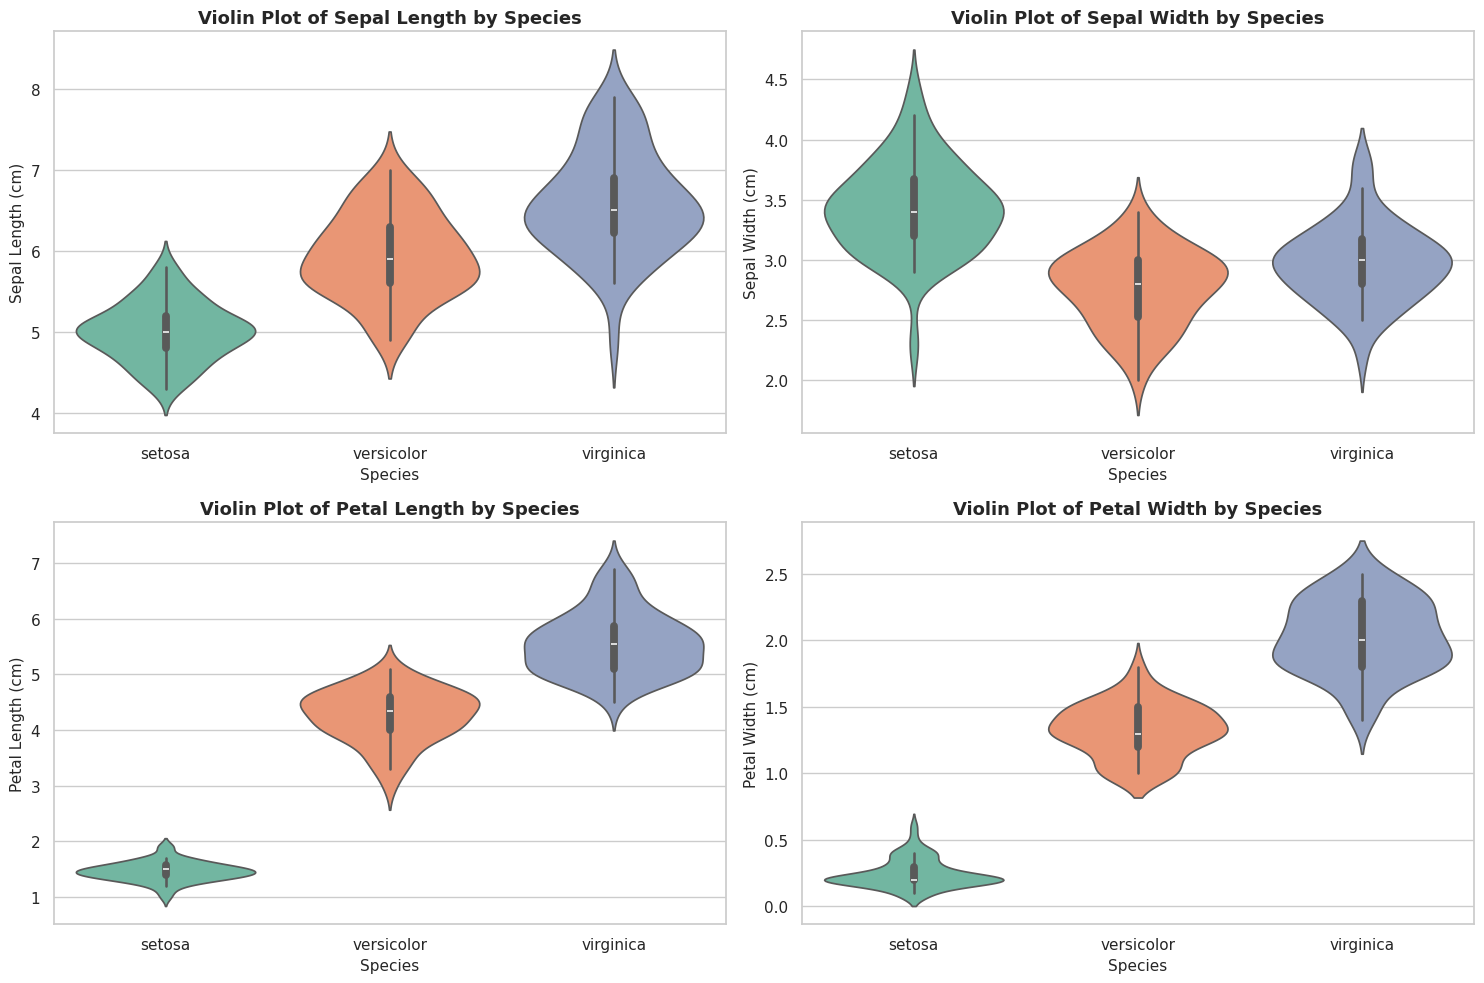

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, feature in zip(axes.flat, features):
    sns.violinplot(
        data=iris,
        x="species",
        y=feature,
        hue="species",
        palette="Set2",
        inner="box",
        legend=False,
        ax=ax
    )
    ax.set_title(f"Violin Plot of {feature.replace('_', ' ').title()} by Species", fontsize=13, fontweight="bold")
    ax.set_xlabel("Species", fontsize=11)
    ax.set_ylabel(f"{feature.replace('_', ' ').title()} (cm)", fontsize=11)

plt.tight_layout()
plt.show()

### Analysis of Violin Plots
1. **Median Progression Across Species:**
   * For `sepal_length`, `petal_length`, and `petal_width`, medians follow a strict monotonic increase from *setosa* $\rightarrow$ *versicolor* $\rightarrow$ *virginica* (e.g., `petal_length` medians: $1.50\text{ cm} \rightarrow 4.35\text{ cm} \rightarrow 5.55\text{ cm}$).
   * Conversely, `sepal_width` breaks this ordering: *setosa* has the highest median ($3.40\text{ cm}$), followed by *virginica* ($3.00\text{ cm}$) and *versicolor* ($2.80\text{ cm}$).
2. **Variance and Interquartile Range (IQR):**
   * *Setosa* exhibits compact violin bodies and narrow IQRs for petal measurements, reflecting tight morphological consistency.
   * *Virginica* consistently shows the widest vertical spread and largest IQRs across `sepal_length` ($\text{SD} = 0.64\text{ cm}$) and `petal_length` ($\text{SD} = 0.55\text{ cm}$), indicating greater natural size variability within that species.
3. **Tail Behavior & Outliers:**
   * Minor upper-tail stretching is visible in *setosa*'s `petal_width` and *virginica*'s `sepal_width`/`sepal_length`, visible as thin tapered violin tips extending beyond the central IQR box.

---
## 4. Heatmaps (Correlation Context)
A correlation heatmap visualizes the pairwise **Pearson correlation coefficients ($r$)** among numerical features, where $r \in [-1, +1]$ measures the strength and direction of linear association.

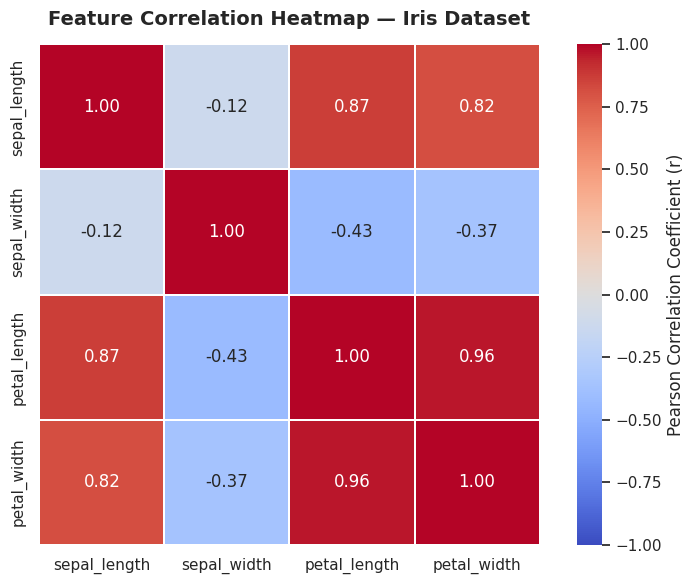

In [5]:
# Compute Pearson correlation matrix across numeric features
corr_matrix = iris.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=1.2,
    cbar_kws={"label": "Pearson Correlation Coefficient (r)"}
)
plt.title("Feature Correlation Heatmap — Iris Dataset", fontsize=14, fontweight="bold", pad=14)
plt.tight_layout()
plt.show()

### Analysis of Heatmap (In the Context of Correlation)
1. **Very Strong Positive Correlations (High Linear Dependence):**
   * **`petal_length` & `petal_width` ($r = 0.96$):** Exhibits the strongest positive correlation in the dataset. As petal length increases, petal width increases almost linearly, indicating substantial shared variance ($R^2 \approx 0.93$) and potential **multicollinearity** if both features are used unregularized in linear models.
   * **`sepal_length` & `petal_length` ($r = 0.87$) and `sepal_length` & `petal_width` ($r = 0.82$):** Both show strong positive linear correlations, demonstrating that overall flower size scales coherently across sepals and petals.
2. **Moderate Negative Correlations & Simpson's Paradox:**
   * **`sepal_width` & `petal_length` ($r = -0.43$) and `sepal_width` & `petal_width` ($r = -0.37$):** Across the pooled dataset, sepal width correlates moderately negatively with both petal dimensions.
   * **Statistical Insight (Simpson's Paradox):** This global negative correlation is driven by species-level grouping—*setosa* possesses uniquely wide sepals paired with very short petals. Within each individual species, `sepal_width` and `petal_length` actually correlate *positively*.
3. **Negligible Linear Correlation:**
   * **`sepal_length` & `sepal_width` ($r = -0.12$):** Shows virtually no linear relationship across the combined dataset ($|r| < 0.20$), confirming that sepal length and sepal width vary nearly independently when species labels are aggregated.

---
## 5. Joint Plots
Joint plots combine a central bivariate visualization with univariate marginal distributions (histograms/KDEs) along the top and right axes, allowing simultaneous inspection of individual feature shapes and their joint relationship.

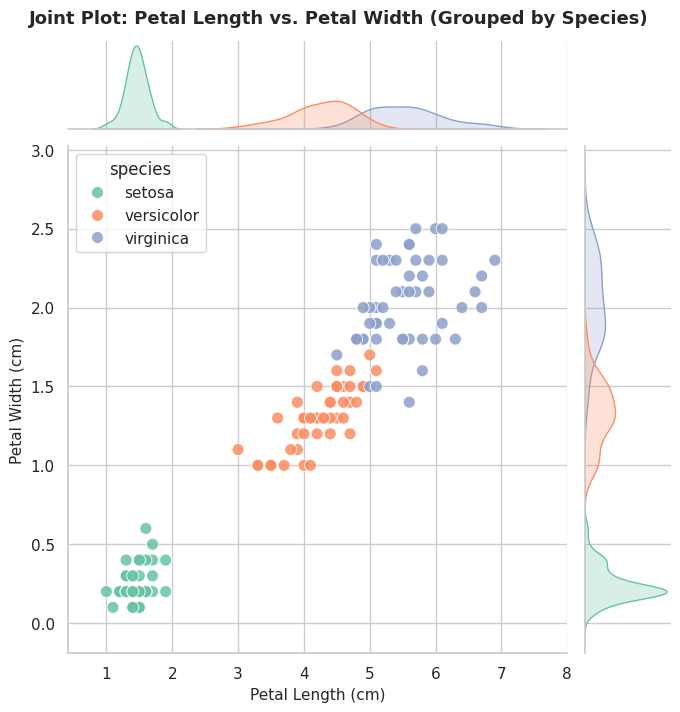

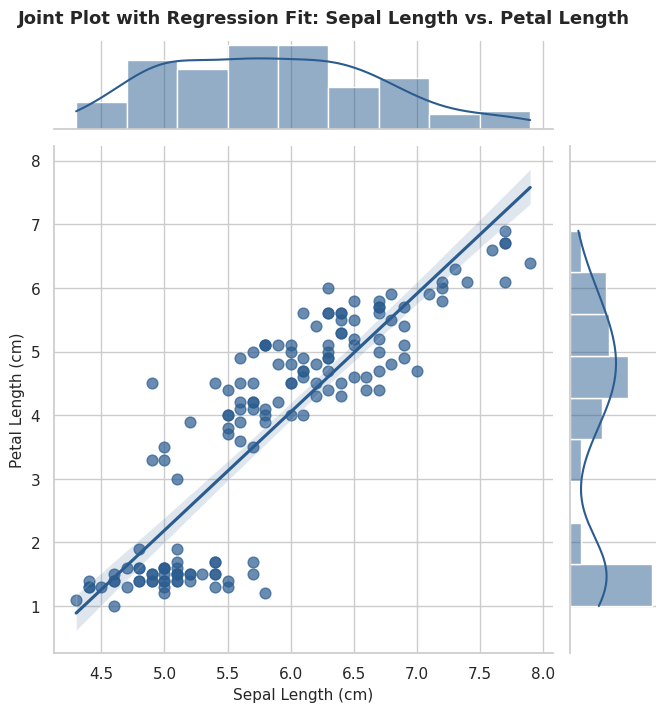

In [6]:
# Joint Plot 1: Species-grouped Scatter + Marginal KDEs
g1 = sns.jointplot(
    data=iris,
    x="petal_length",
    y="petal_width",
    hue="species",
    height=7,
    s=75,
    alpha=0.85
)
g1.fig.suptitle("Joint Plot: Petal Length vs. Petal Width (Grouped by Species)", y=1.02, fontsize=13, fontweight="bold")
g1.set_axis_labels("Petal Length (cm)", "Petal Width (cm)", fontsize=11)
plt.show()

# Joint Plot 2: Linear Regression + Marginal Histogram/KDE
g2 = sns.jointplot(
    data=iris,
    x="sepal_length",
    y="petal_length",
    kind="reg",
    color="#2b5c8f",
    height=7,
    scatter_kws={"alpha": 0.7, "s": 60}
)
g2.fig.suptitle("Joint Plot with Regression Fit: Sepal Length vs. Petal Length", y=1.02, fontsize=13, fontweight="bold")
g2.set_axis_labels("Sepal Length (cm)", "Petal Length (cm)", fontsize=11)
plt.show()

### Analysis of Joint Plots
1. **Joint Scatter & Marginal KDE (`petal_length` vs. `petal_width`):**
   * **Central Panel:** Confirms tight linear alignment along a diagonal axis from *setosa* (lower left) through *versicolor* (center) to *virginica* (upper right).
   * **Marginal Panels:** The top and right KDE curves illustrate why *setosa* is cleanly separable—its marginal density peaks are separated by a clear gap ($pprox 1.9	ext{ cm}$ to $3.0	ext{ cm}$ in petal length; $pprox 0.6	ext{ cm}$ to $1.0	ext{ cm}$ in petal width) from the other two species.
2. **Joint Regression Fit (`sepal_length` vs. `petal_length`):**
   * **Linear Trend & Confidence Band:** The ordinary least squares (OLS) regression line slopes steeply upward with a narrow 95% confidence interval, visually reflecting the strong correlation ($r = 0.87$).
   * **Bimodal Marginal Distribution:** The right marginal distribution for `petal_length` reveals a prominent bimodal structure—one distinct peak around $1.5	ext{ cm}$ (*setosa*) and a broader combined peak between $4.0	ext{ cm}$ and $6.0	ext{ cm}$ (*versicolor* + *virginica*).

---
## 6. Pair Plots
A pair plot generates an $N \times N$ grid of plots across all numerical variables—displaying pairwise scatter plots on the off-diagonals and univariate KDE distributions along the main diagonal.

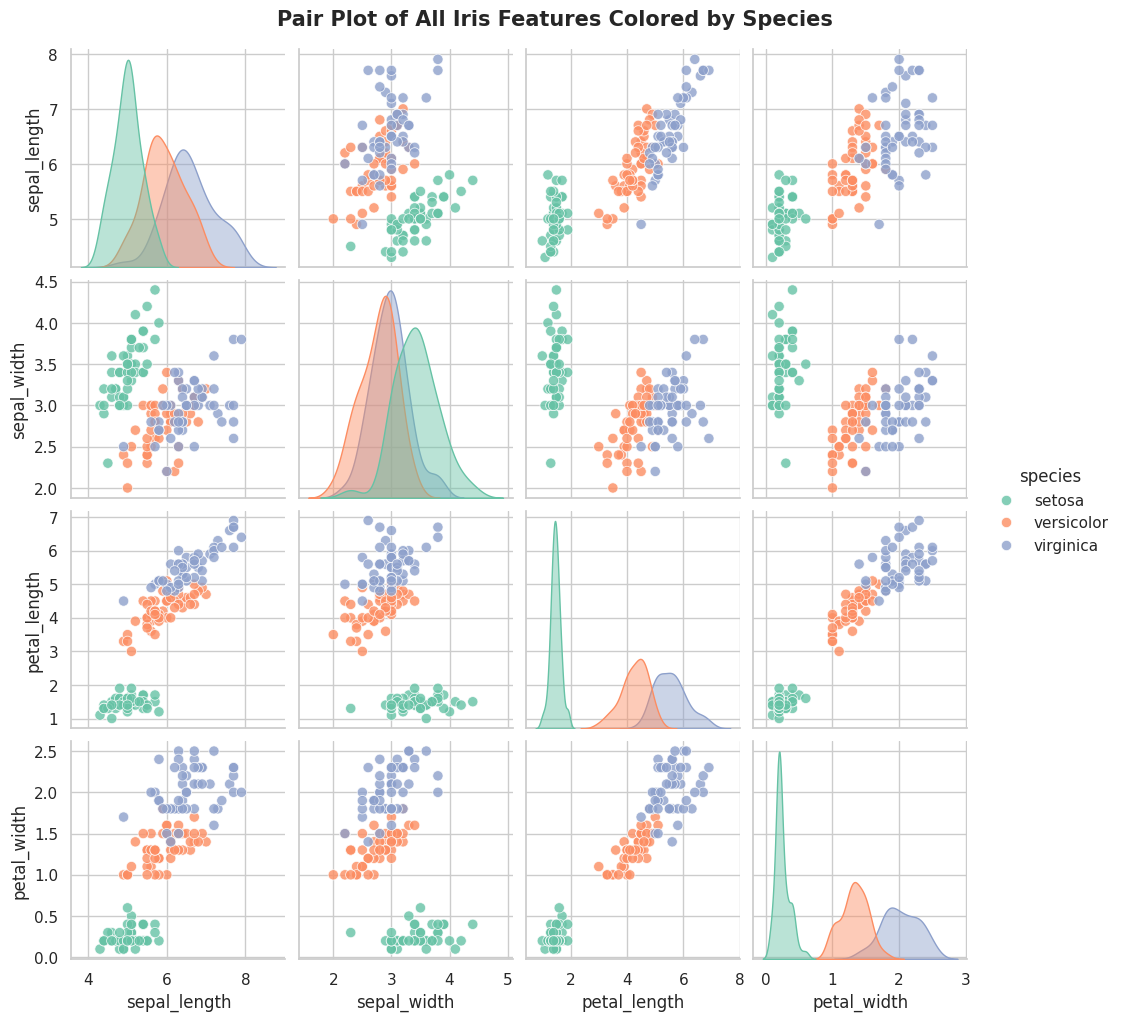

In [7]:
pair_grid = sns.pairplot(
    data=iris,
    hue="species",
    diag_kind="kde",
    palette="Set2",
    plot_kws={"alpha": 0.8, "s": 55},
    diag_kws={"fill": True, "alpha": 0.45}
)
pair_grid.fig.suptitle("Pair Plot of All Iris Features Colored by Species", y=1.02, fontsize=15, fontweight="bold")
plt.show()

### Analysis of Pair Plots
1. **Holistic Multivariate Comparison:**
   * In a single $4 \times 4$ matrix (12 pairwise scatter panels + 4 diagonal KDE panels), the pair plot synthesizes all bivariate and univariate relationships across the Iris dataset.
2. **Best Feature Pairs for Classification:**
   * Panels involving **`petal_length` and `petal_width`** provide the cleanest class separation, making them the strongest predictors for machine learning classification tasks.
   * Panels pairing **`sepal_length` and `sepal_width`** show substantial overlap between *versicolor* and *virginica*, confirming they are less effective in isolation.
3. **Diagnostic Overview of Within-Class vs. Between-Class Trends:**
   * Looking across rows and columns reveals how *Iris setosa* consistently occupies a distinct region of feature space across every bivariate combination, whereas *versicolor* and *virginica* sit adjacent along a continuous size gradient.

---
## Summary of Key Findings
* **Most Discriminative Features:** `petal_length` and `petal_width` cleanly isolate *Iris setosa* and best separate *versicolor* from *virginica*.
* **Strongest Correlation:** `petal_length` and `petal_width` exhibit a near-perfect positive linear correlation ($r = 0.96$).
* **Most Overlapped Feature:** `sepal_width` shows heavy distributional overlap across all three species and demonstrates Simpson's Paradox when correlated globally ($r = -0.43$ with `petal_length`) versus within species.